# Thermal Dataset 2 Exploratory Data Analysis

This notebook documents the Dataset 2 thermal-video subset used for the current drone-versus-bird analysis. It reads validated manifests and source annotations without changing raw data. The analysis covers class counts, recording duration, annotation issues, bounding-box geometry, target location, and temporal dependence.

Run the source-manifest validation stage in `02_thermal_ir_pipeline.ipynb` before running this notebook.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from mcos_decoder import load_groundtruth

WORKING_DIRECTORY = Path.cwd().resolve()
if (WORKING_DIRECTORY / '.git').is_dir():
    REPO_ROOT = WORKING_DIRECTORY
elif (WORKING_DIRECTORY.parent / '.git').is_dir():
    REPO_ROOT = WORKING_DIRECTORY.parent
else:
    raise RuntimeError('Run this notebook from the repository root or notebooks directory.')

THERMAL_ROOT = REPO_ROOT / 'data' / 'thermal-ir'
MANIFEST_PATH = THERMAL_ROOT / 'manifests' / 'dataset2_videos.csv'
ISSUES_PATH = THERMAL_ROOT / 'manifests' / 'annotation_issues.csv'
BOX_SUMMARY_PATH = THERMAL_ROOT / 'interim' / 'eda' / 'dataset2_box_summary.csv'
FIGURE_DIR = REPO_ROOT / 'results' / 'thermal-ir' / 'eda' / 'dataset2'

for required_path in (MANIFEST_PATH, ISSUES_PATH):
    if not required_path.is_file():
        raise FileNotFoundError(f'Missing {required_path}. Run 02_thermal_ir_pipeline.ipynb first.')

BOX_SUMMARY_PATH.parent.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 120


## 1. Recording inventory, duration, and annotation issues

Drone and bird recordings form the current analysis subset. Airplane and helicopter recordings remain in the source manifest for provenance, but are excluded from these drone-versus-bird summaries.

,recordings,video_frames,annotation_entries,visible_annotations,duration_seconds_median,recordings_with_length_mismatch
source_class,,,,,,
BIRD,79,24854,24544,21967,10.47,79
DRONE,157,49043,49187,47622,10.40,4


,count
issue_type,
video_annotation_length_mismatch,85


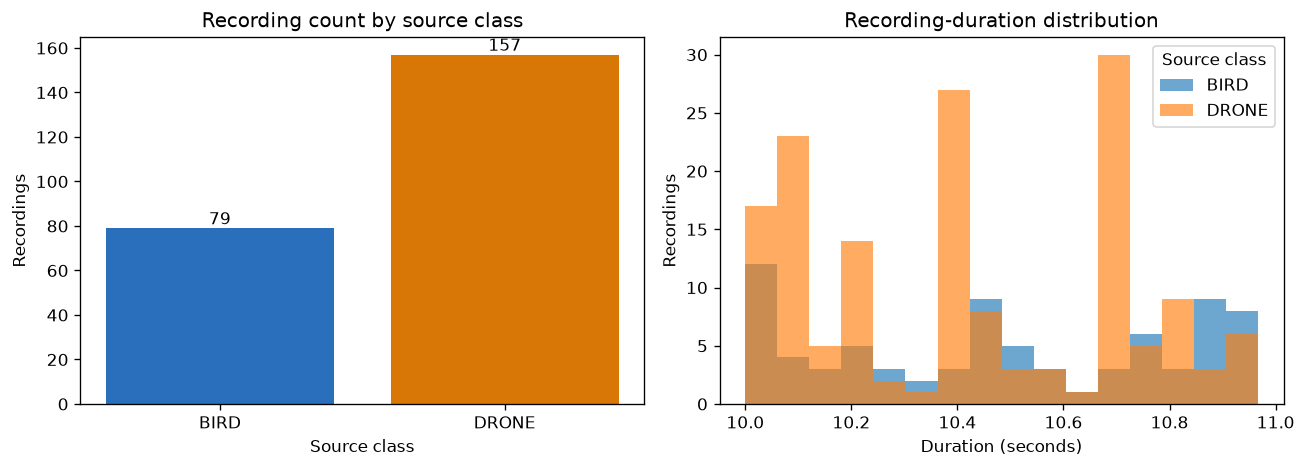

In [2]:
videos = pd.read_csv(MANIFEST_PATH)
issues = pd.read_csv(ISSUES_PATH)
eligible = videos.loc[videos['export_policy'].isin(['positive_drone', 'negative_bird'])].copy()
eligible['duration_seconds'] = eligible['video_frame_count'] / eligible['fps']
eligible['frame_annotation_difference'] = eligible['video_frame_count'] - eligible['annotation_entries']
eligible['length_mismatch'] = eligible['frame_annotation_difference'].ne(0)

inventory = (
    eligible.groupby('source_class')
    .agg(
        recordings=('source_sequence', 'count'),
        video_frames=('video_frame_count', 'sum'),
        annotation_entries=('annotation_entries', 'sum'),
        visible_annotations=('visible_entries', 'sum'),
        duration_seconds_median=('duration_seconds', 'median'),
        recordings_with_length_mismatch=('length_mismatch', 'sum'),
    )
    .round(2)
)
display(inventory)

issue_counts = (
    issues.loc[issues['source_dataset'].eq('drone_detection_dataset2')]
    .groupby('issue_type').size().rename('count').to_frame()
)
display(issue_counts)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = eligible['source_class'].value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color=['#2a6fbb', '#d97706'])
axes[0].set(title='Recording count by source class', xlabel='Source class', ylabel='Recordings')
for index, value in enumerate(counts.values):
    axes[0].text(index, value, str(value), ha='center', va='bottom')
for source_class, group in eligible.groupby('source_class'):
    axes[1].hist(group['duration_seconds'], bins=16, alpha=0.65, label=source_class)
axes[1].set(title='Recording-duration distribution', xlabel='Duration (seconds)', ylabel='Recordings')
axes[1].legend(title='Source class')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'recording_counts_and_durations.png', bbox_inches='tight')
plt.show()


## 2. Bounding-box area, aspect ratio, and target location

The source annotations are decoded for both drone and bird recordings. Bird boxes are descriptive EDA information only; the one-class derived dataset continues to use empty labels for bird frames. Invalid or out-of-frame boxes are omitted from geometry summaries and counted.

In [3]:
def valid_xywh(box, image_width, image_height):
    if box is None or len(box) != 4:
        return False
    x, y, width, height = (float(value) for value in box)
    return (
        np.isfinite([x, y, width, height]).all()
        and width > 0 and height > 0
        and x >= 0 and y >= 0
        and x + width <= image_width and y + height <= image_height
    )

box_rows, invalid_box_count = [], 0
for record in eligible.itertuples(index=False):
    annotation_path = REPO_ROOT / record.annotation_path
    for frame_number, box in enumerate(load_groundtruth(annotation_path), start=1):
        if box is None:
            continue
        if not valid_xywh(box, record.image_width, record.image_height):
            invalid_box_count += 1
            continue
        x, y, width, height = (float(value) for value in box)
        area = width * height
        box_rows.append({
            'source_sequence': record.source_sequence,
            'source_class': record.source_class,
            'frame_number': frame_number,
            'area_pixels': area,
            'area_fraction': area / (record.image_width * record.image_height),
            'aspect_ratio': width / height,
            'center_x_fraction': (x + width / 2) / record.image_width,
            'center_y_fraction': (y + height / 2) / record.image_height,
        })

boxes = pd.DataFrame(box_rows)
if boxes.empty:
    raise ValueError('No valid boxes were decoded; inspect the source manifest and mcos-decoder installation.')
boxes.to_csv(BOX_SUMMARY_PATH, index=False)
print(f'Wrote {len(boxes):,} valid boxes to {BOX_SUMMARY_PATH.relative_to(REPO_ROOT)}')
print(f'Excluded {invalid_box_count:,} invalid source boxes from geometry summaries.')

geometry_summary = (
    boxes.groupby('source_class')
    .agg(
        boxes=('frame_number', 'count'),
        median_area_pixels=('area_pixels', 'median'),
        median_area_fraction=('area_fraction', 'median'),
        median_aspect_ratio=('aspect_ratio', 'median'),
        median_center_x=('center_x_fraction', 'median'),
        median_center_y=('center_y_fraction', 'median'),
    )
    .round(4)
)
display(geometry_summary)


Wrote 69,589 valid boxes to data\thermal-ir\interim\eda\dataset2_box_summary.csv
Excluded 0 invalid source boxes from geometry summaries.


,boxes,median_area_pixels,median_area_fraction,median_aspect_ratio,median_center_x,median_center_y
source_class,,,,,,
BIRD,21967,177.6667,0.0022,1.1224,0.4781,0.4422
DRONE,47622,218.8867,0.0027,1.4990,0.5747,0.3895


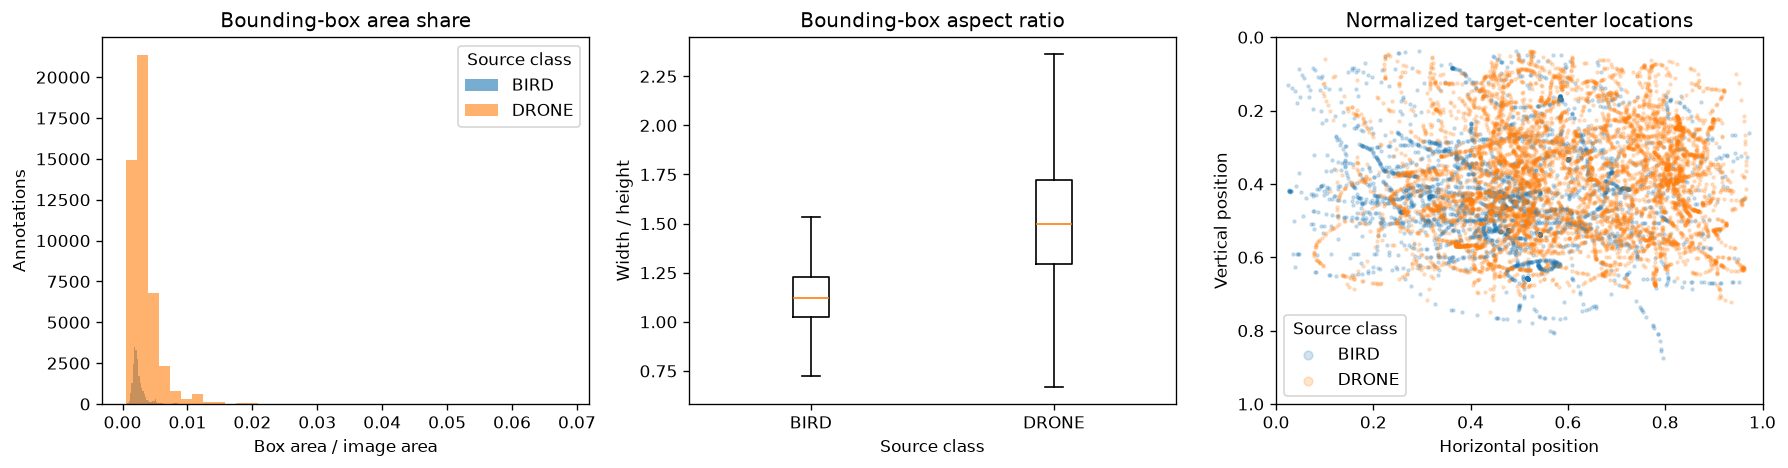

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for source_class, group in boxes.groupby('source_class'):
    axes[0].hist(group['area_fraction'], bins=40, alpha=0.6, label=source_class)
axes[0].set(title='Bounding-box area share', xlabel='Box area / image area', ylabel='Annotations')
axes[0].legend(title='Source class')

aspect_groups = [group['aspect_ratio'].values for _, group in boxes.groupby('source_class')]
aspect_labels = [name for name, _ in boxes.groupby('source_class')]
axes[1].boxplot(aspect_groups, tick_labels=aspect_labels, showfliers=False)
axes[1].set(title='Bounding-box aspect ratio', xlabel='Source class', ylabel='Width / height')

sample = boxes.sample(n=min(10000, len(boxes)), random_state=42)
for source_class, group in sample.groupby('source_class'):
    axes[2].scatter(group['center_x_fraction'], group['center_y_fraction'], s=3, alpha=0.2, label=source_class)
axes[2].set(title='Normalized target-center locations', xlabel='Horizontal position', ylabel='Vertical position', xlim=(0, 1), ylim=(1, 0))
axes[2].legend(title='Source class', markerscale=3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'box_geometry_and_target_location.png', bbox_inches='tight')
plt.show()


## 3. Report-ready EDA checklist

Use the displayed tables and saved figures to describe recording-level class counts, video-duration variation, known annotation mismatches, target-size and aspect-ratio variation, target-location concentration, and temporal dependence within recordings. The generated CSV and PNG files are derived artifacts; raw videos, raw annotations, and source manifests remain unchanged.